# Dengue: download completo e CSV único no Google Colab

1. Abra este `.ipynb` em https://colab.research.google.com/ usando **Arquivo → Fazer upload de notebook**.
2. Conecte-se a um ambiente hospedado do Colab (CPU é suficiente; GPU não acelera este pipeline).
3. Ajuste as opções abaixo e use **Ambiente de execução → Executar tudo**.
4. Se `SALVAR_NO_DRIVE = True`, autorize a montagem do seu Drive quando solicitado.

Este notebook já contém o script completo; não precisa clonar o repositório, enviar ZIPs nem instalar bibliotecas. Baixa todos os arquivos novamente em cada execução, descompacta em fluxo e cria um CSV único. Não reutiliza downloads, metadados ou checkpoints antigos.

O erro `No space left on device` é de **armazenamento em disco**, não de RAM. O Colab também tem limites: o espaço disponível será exibido antes de começar. O CSV com a união de colunas pode ser maior que o volume descompactado dos ZIPs.


In [4]:
from pathlib import Path
import shutil

THREADS = 20
SALVAR_NO_DRIVE = False
PASTA_NO_DRIVE = "Denguinhos/datasets"  # pasta dentro de Meu Drive

TRABALHO = Path("/content/sinan-dengue")
TRABALHO.mkdir(parents=True, exist_ok=True)
SCRIPT = TRABALHO / "baixar-sinan-dengue-arquivos.py"
DADOS = TRABALHO / "dados"
CSV_FINAL = DADOS / "dengue-completo.csv"

if THREADS < 1:
    raise ValueError("THREADS deve ser positivo")
print(f"Downloads simultâneos: {THREADS}")
print(f"Disco livre no Colab: {shutil.disk_usage(TRABALHO).free / 1024**3:.2f} GiB")
print(f"CSV a gerar: {CSV_FINAL}")


Downloads simultâneos: 20
Disco livre no Colab: 107.62 GiB
CSV a gerar: /content/sinan-dengue/dados/dengue-completo.csv


## Script incorporado

A próxima célula grava no ambiente Colab uma cópia do pipeline. Ela não executa downloads ainda. Você pode recolher essa célula; não precisa editar seu conteúdo.


In [5]:
PIPELINE_SOURCE = '#!/usr/bin/env python3\n"""Baixa do zero os ZIPs oficiais de dengue e consolida um CSV ordenado por ano de origem."""\nimport argparse\nimport csv\nimport errno\nimport io\nfrom operator import itemgetter\nfrom concurrent.futures import ThreadPoolExecutor, as_completed\nfrom html.parser import HTMLParser\nfrom http.client import IncompleteRead\nimport json\nfrom pathlib import Path, PurePosixPath\nimport re\nimport shutil\nimport sys\nimport time\nfrom urllib.error import HTTPError\nfrom urllib.parse import unquote, urlparse\nfrom urllib.request import Request, urlopen\nimport zipfile\nfrom contextlib import contextmanager\n\nCATALOG = \'https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue\'\nDEFAULT_OUTPUT = Path(__file__).resolve().parents[1] / \'data/sinan-arquivos\'\nBLOCK = 1024 * 1024\n\n\ndef request(url, method=\'GET\', headers=None):\n    return urlopen(Request(url, method=method, headers={\'User-Agent\': \'Denguinhos-dataset-downloader/1.0\', **(headers or {})}), timeout=120)\n\n\ndef retry(operation):\n    for attempt in range(6):\n        try:\n            return operation()\n        except (OSError, EOFError, IncompleteRead) as error:\n            if isinstance(error, OSError) and error.errno in (errno.ENOSPC, errno.EDQUOT, errno.EACCES):\n                raise\n            if isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504):\n                raise\n            if attempt == 5:\n                raise\n            delay = min(30, 2 ** attempt)\n            print(f\'Falha temporária: {error}; nova tentativa em {delay}s\', flush=True)\n            time.sleep(delay)\n\n\nclass CatalogParser(HTMLParser):\n    def __init__(self):\n        super().__init__()\n        self.capturing = False\n        self.parts = []\n\n    def handle_starttag(self, tag, attrs):\n        if tag == \'script\' and dict(attrs).get(\'id\') == \'__NEXT_DATA__\':\n            self.capturing = True\n\n    def handle_data(self, data):\n        if self.capturing:\n            self.parts.append(data)\n\n    def handle_endtag(self, tag):\n        if tag == \'script\':\n            self.capturing = False\n\n\ndef resources_from_html(html):\n    parser = CatalogParser()\n    parser.feed(html)\n    payload = json.loads(\'\'.join(parser.parts))\n    resources = payload[\'props\'][\'pageProps\'][\'resources\']\n    selected = {}\n    for resource in resources:\n        url = resource.get(\'url\', \'\')\n        path = urlparse(url).path.lower()\n        if resource.get(\'state\', \'active\') != \'active\':\n            continue\n        if resource.get(\'format\', \'\').upper() != \'CSV\' and not path.endswith((\'.csv\', \'.csv.zip\')):\n            continue\n        if urlparse(url).scheme != \'https\':\n            raise ValueError(f\'URL de download inesperada: {url}\')\n        if not path.endswith((\'.zip\', \'.csv\')):\n            raise ValueError(f\'Recurso CSV sem arquivo reconhecido: {url}\')\n        selected[url] = resource\n    if not selected:\n        raise ValueError(\'Nenhum CSV encontrado no catálogo. A estrutura do portal pode ter mudado.\')\n    return list(selected.values())\n\n\ndef load_catalog():\n    def load():\n        with request(CATALOG) as response:\n            return resources_from_html(response.read().decode(\'utf-8\'))\n    return retry(load)\n\n\ndef write_json(path, payload):\n    temporary = path.with_suffix(path.suffix + \'.tmp\')\n    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2) + \'\\n\')\n    temporary.replace(path)\n\n\ndef download(resource, folder):\n    """Cada execução e cada tentativa baixa o arquivo inteiro, sem consultar cache."""\n    url = resource[\'url\']\n    name = Path(unquote(urlparse(url).path)).name\n    if name in (\'\', \'.\', \'..\'):\n        raise ValueError(\'Nome de arquivo inválido\')\n    target = folder / name\n    partial = target.with_suffix(target.suffix + \'.part\')\n\n    def transfer():\n        with request(url) as response:\n            if response.status != 200:\n                raise ValueError(f\'Resposta HTTP inesperada: {response.status}\')\n            size_header = response.headers.get(\'Content-Length\')\n            expected = int(size_header) if size_header is not None else None\n            with partial.open(\'wb\') as stream:\n                shutil.copyfileobj(response, stream, BLOCK)\n            size = partial.stat().st_size\n            if expected is not None and size != expected:\n                raise OSError(f\'Download incompleto: {name}\')\n            return {\'url\': url, \'etag\': response.headers.get(\'ETag\'), \'size\': size,\n                    \'modified\': response.headers.get(\'Last-Modified\')}\n    print(f\'Baixando do zero: {name}\', flush=True)\n    identity = retry(transfer)\n    partial.replace(target)\n    return target, identity\n\n\ndef extract(archive, output, identity):\n    destination = output / archive.name.removesuffix(\'.zip\')\n    destination.mkdir(parents=True, exist_ok=True)\n    marker = destination / \'extracao.json\'\n    results = []\n    if archive.suffix.lower() == \'.zip\':\n        with zipfile.ZipFile(archive) as zipped:\n            members = [member for member in zipped.infolist() if not member.is_dir() and member.filename.lower().endswith(\'.csv\')]\n            if not members:\n                raise ValueError(f\'ZIP não contém CSV: {archive.name}\')\n            for member in members:\n                parts = PurePosixPath(member.filename)\n                if parts.is_absolute() or \'..\' in parts.parts or \'\\\\\' in member.filename or \':\' in member.filename:\n                    raise ValueError(f\'Caminho inválido no ZIP: {member.filename}\')\n                target = destination / Path(*parts.parts)\n                target.parent.mkdir(parents=True, exist_ok=True)\n                temporary = target.with_suffix(target.suffix + \'.part\')\n                temporary.unlink(missing_ok=True)\n                if shutil.disk_usage(destination).free < member.file_size:\n                    raise OSError(errno.ENOSPC, f\'Espaço insuficiente para extrair {member.filename} ({member.file_size / BLOCK:.1f} MiB)\')\n                # A leitura até EOF verifica o CRC do ZIP, sem carregar o CSV em memória.\n                try:\n                    with zipped.open(member) as source, temporary.open(\'wb\') as stream:\n                        shutil.copyfileobj(source, stream, BLOCK)\n                except BaseException:\n                    temporary.unlink(missing_ok=True)\n                    raise\n                temporary.replace(target)\n                results.append({\'arquivo\': member.filename, \'bytes\': member.file_size})\n    else:\n        target = destination / archive.name\n        temporary = target.with_suffix(target.suffix + \'.part\')\n        shutil.copyfile(archive, temporary)\n        temporary.replace(target)\n        results.append({\'arquivo\': archive.name, \'bytes\': target.stat().st_size})\n    write_json(marker, {\'origem\': identity, \'csvs\': results})\n    print(f\'Descompactado: {archive.name} ({len(results)} CSV)\', flush=True)\n    return results\n\n\ndef process(resource, output, extract_files=False):\n    archive, identity = download(resource, output / \'zips\')\n    if not extract_files:\n        return {\'recurso\': resource[\'name\'], \'url\': resource[\'url\'], \'arquivo\': str(archive), \'origem\': identity, \'concluido\': True}\n    csvs = extract(archive, output / \'csv\', identity)\n    return {\'recurso\': resource[\'name\'], \'url\': resource[\'url\'], \'arquivo\': str(archive), \'origem\': identity, \'csvs\': csvs, \'concluido\': True}\n\n\ndef resource_year(resource):\n    match = re.search(r\'\\b(20\\d{2}|19\\d{2})\\b\', resource[\'recurso\'])\n    if not match:\n        raise ValueError(f\'Ano não identificado no recurso: {resource["recurso"]}\')\n    return int(match[1])\n\n\n@contextmanager\ndef csv_source(spec, encoding):\n    archive = Path(spec[\'arquivo\'])\n    if spec[\'membro\'] is None:\n        with archive.open(\'r\', encoding=encoding, newline=\'\') as stream:\n            yield stream\n    else:\n        with zipfile.ZipFile(archive) as zipped, zipped.open(spec[\'membro\']) as raw:\n            with io.TextIOWrapper(raw, encoding=encoding, newline=\'\') as stream:\n                yield stream\n\n\ndef inspect_sources(results, encoding):\n    specs, columns = [], [\'ANO_ARQUIVO\']\n    for result in sorted(results, key=lambda item: (resource_year(item), item[\'url\'])):\n        archive = Path(result[\'arquivo\'])\n        if archive.suffix.lower() == \'.zip\':\n            with zipfile.ZipFile(archive) as zipped:\n                members = sorted((i.filename, i.file_size) for i in zipped.infolist() if not i.is_dir() and i.filename.lower().endswith(\'.csv\'))\n        else:\n            members = [(None, archive.stat().st_size)]\n        if not members:\n            raise ValueError(f\'Arquivo sem CSV: {archive}\')\n        for member, size in members:\n            spec = {\'arquivo\': str(archive), \'membro\': member, \'bytes\': size, \'ano\': resource_year(result), \'origem\': result[\'origem\']}\n            with csv_source(spec, encoding) as stream:\n                first_line = stream.readline()\n                try:\n                    delimiter = csv.Sniffer().sniff(first_line, delimiters=\',;\\t\').delimiter\n                except csv.Error:\n                    if any(character in first_line for character in \',;\\t\'):\n                        raise\n                    delimiter = \',\'  # CSV com uma única coluna\n                header = [name.strip().upper() for name in next(csv.reader([first_line], delimiter=delimiter))]\n            if not header or any(not name for name in header) or len(set(header)) != len(header) or \'ANO_ARQUIVO\' in header:\n                raise ValueError(f\'Cabeçalho inválido ou repetido: {archive} / {member}\')\n            spec.update(colunas=header, delimitador=delimiter)\n            specs.append(spec)\n            columns.extend(name for name in header if name not in columns)\n    return specs, columns\n\n\ndef consolidate(results, output, encoding=\'utf-8-sig\'):\n    """Reconstrói integralmente o CSV em fluxo a partir dos downloads desta execução."""\n    output.parent.mkdir(parents=True, exist_ok=True)\n    specs, columns = inspect_sources(results, encoding)\n    manifest_path = output.with_suffix(\'.manifest.json\')\n    temporary = output.with_suffix(output.suffix + \'.part\')\n    state = {\'registros\': 0, \'por_ano_arquivo\': {}}\n    # Limite inferior: união de colunas pode produzir um resultado ainda maior.\n    minimum = sum(spec[\'bytes\'] for spec in specs)\n    if shutil.disk_usage(output.parent).free < minimum:\n        raise OSError(errno.ENOSPC, f\'Consolidação precisa de pelo menos {minimum / 1024**3:.2f} GiB livres; a união de colunas pode exigir mais. Use --output em um disco com espaço.\')\n    with temporary.open(\'w\', encoding=\'utf-8\', newline=\'\', buffering=BLOCK) as stream:\n        writer = csv.writer(stream, lineterminator=\'\\n\')\n        writer.writerow(columns)\n        for index in range(len(specs)):\n            spec = specs[index]\n            source_columns = spec[\'colunas\']\n            positions = {name: position for position, name in enumerate(source_columns)}\n            # itemgetter remapeia as colunas em C, sem um dict por registro.\n            reorder = itemgetter(*(positions.get(name, len(source_columns)) for name in columns[1:]))\n            count = 0\n            year = str(spec[\'ano\'])\n            with csv_source(spec, encoding) as source:\n                reader = csv.reader(source, delimiter=spec[\'delimitador\'], strict=True)\n                next(reader)\n                for row in reader:\n                    if len(row) != len(source_columns):\n                        raise ValueError(f\'Quantidade de campos inválida: {spec["arquivo"]}, linha {reader.line_num}\')\n                    row.append(\'\')\n                    values = reorder(row)\n                    if len(columns) == 2:\n                        values = (values,)\n                    writer.writerow((year,) + values)\n                    count += 1\n            stream.flush()\n            state[\'registros\'] += count\n            state[\'por_ano_arquivo\'][year] = state[\'por_ano_arquivo\'].get(year, 0) + count\n            print(f\'Consolidado {year}: {count:,} registros | fontes: {index + 1}/{len(specs)} | total: {state["registros"]:,}\', flush=True)\n    temporary.replace(output)\n    manifest = {**state, \'bytes\': output.stat().st_size, \'colunas\': columns, \'encoding\': encoding, \'fontes\': specs,\n                \'ordenacao\': \'ANO_ARQUIVO crescente; ordem original dentro de cada arquivo\', \'concluido\': True}\n    write_json(manifest_path, manifest)\n    return manifest\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--output-dir\', type=Path, default=DEFAULT_OUTPUT)\n    parser.add_argument(\'--threads\', type=int, default=4, help=\'Downloads de arquivos simultâneos (padrão: 4).\')\n    parser.add_argument(\'--output\', type=Path, help=\'CSV consolidado (padrão: OUTPUT_DIR/dengue-completo.csv).\')\n    parser.add_argument(\'--encoding\', default=\'utf-8-sig\', help=\'Codificação dos CSVs de origem.\')\n    parser.add_argument(\'--extract-files\', action=\'store_true\', help=\'Também grava cópias individuais descompactadas (usa mais disco).\')\n    parser.add_argument(\'--list-only\', action=\'store_true\', help=\'Lista os recursos sem baixar.\')\n    args = parser.parse_args()\n    if args.threads < 1:\n        parser.error(\'--threads deve ser positivo\')\n    resources = load_catalog()\n    print(f\'Catálogo: {len(resources)} arquivos CSV disponíveis.\', flush=True)\n    if args.list_only:\n        for resource in resources:\n            print(resource[\'name\'], resource[\'url\'])\n        return\n    (args.output_dir / \'zips\').mkdir(parents=True, exist_ok=True)\n    write_json(args.output_dir / \'catalogo.json\', {\'fonte\': CATALOG, \'resources\': resources})\n    print(\'Etapa 1/2: baixando todos os arquivos do catálogo.\', flush=True)\n    results = []\n    with ThreadPoolExecutor(max_workers=args.threads) as pool:\n        futures = {pool.submit(process, resource, args.output_dir, args.extract_files): resource for resource in resources}\n        for future in as_completed(futures):\n            resource = futures[future]\n            try:\n                results.append(future.result())\n            except Exception as error:\n                print(f\'Falha em {resource["name"]}: {error}\', file=sys.stderr, flush=True)\n                results.append({\'recurso\': resource[\'name\'], \'url\': resource[\'url\'], \'concluido\': False, \'erro\': str(error)})\n            write_json(args.output_dir / \'manifesto.json\', {\'fonte\': CATALOG, \'total\': len(resources), \'resultados\': results})\n            print(f\'Progresso: {len(results)}/{len(resources)} arquivos processados\', flush=True)\n    if any(not result[\'concluido\'] for result in results):\n        raise ValueError(\'Alguns arquivos falharam. Execute novamente para baixar tudo do zero.\')\n    output = args.output or args.output_dir / \'dengue-completo.csv\'\n    print(f\'Etapa 2/2: descompactando os ZIPs e reunindo todos os registros em {output}, por ano crescente.\', flush=True)\n    manifest = consolidate(results, output, args.encoding)\n    print(f\'Pipeline concluído: {output} | {manifest["registros"]:,} registros\', flush=True)\n    return output\n\n\nif __name__ == \'__main__\':\n    try:\n        main()\n    except KeyboardInterrupt:\n        print(\'Interrompido. A próxima execução baixará tudo do zero.\', file=sys.stderr)\n        sys.exit(130)\n    except Exception as error:\n        print(f\'Erro: {error}\', file=sys.stderr)\n        sys.exit(1)\n'
SCRIPT.write_text(PIPELINE_SOURCE, encoding="utf-8")
print(f"Script preparado: {SCRIPT}")


Script preparado: /content/sinan-dengue/baixar-sinan-dengue-arquivos.py


## Destino persistente opcional

Os downloads e a consolidação usam o disco do Colab para evitar o custo de gravar milhões de linhas diretamente no Drive. Ao terminar, o CSV pronto e seu manifesto serão copiados para o Drive, se ativado. É necessário espaço para o CSV também na sua conta do Drive.

O disco do ambiente Colab é temporário: se a sessão for descartada, os arquivos locais podem ser perdidos. A montagem e a cópia seguem o [guia oficial de acesso a dados do Colab](https://colab.research.google.com/notebooks/io.ipynb); veja também a [FAQ oficial](https://research.google.com/colaboratory/faq.html).


In [6]:
if SALVAR_NO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    relativo = Path(PASTA_NO_DRIVE)
    if relativo.is_absolute() or ".." in relativo.parts:
        raise ValueError("PASTA_NO_DRIVE deve ser relativa à pasta Meu Drive")
    DESTINO_DRIVE = Path("/content/drive/MyDrive") / relativo
    DESTINO_DRIVE.mkdir(parents=True, exist_ok=True)
    print(f"Destino persistente: {DESTINO_DRIVE}")
else:
    print("Saída apenas no disco temporário do Colab.")


Saída apenas no disco temporário do Colab.


## Baixar, descompactar e consolidar

Esta etapa sempre baixa tudo do zero. O progresso aparece abaixo. Só publica `dengue-completo.csv` após reunir todos os arquivos com sucesso. Falhas em download, integridade, parsing ou espaço em disco interrompem a geração; uma nova execução começa novamente do zero.

A ordenação é por **`ANO_ARQUIVO` crescente**, começando em 2000 conforme os recursos publicados no catálogo. A ordem original dentro de cada ano é mantida. Não há ordenação diária por `DT_NOTIFIC`: um arquivo anual pode conter notificações de outro ano. Para série diária, escolha a data de referência na preparação do modelo.


In [7]:
import subprocess
import sys
import time

PIPELINE_OK = False
inicio = time.monotonic()
comando = [sys.executable, "-u", str(SCRIPT),
           "--output-dir", str(DADOS), "--output", str(CSV_FINAL),
           "--threads", str(THREADS)]
with subprocess.Popen(comando, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, encoding="utf-8", errors="replace", bufsize=1) as processo:
    try:
        for linha in processo.stdout:
            print(linha, end="", flush=True)
        codigo = processo.wait()
    except BaseException:
        processo.terminate()
        processo.wait()
        raise
if codigo:
    raise RuntimeError(f"Pipeline falhou (código {codigo}). Consulte a mensagem acima. Nada será copiado para o Drive.")
PIPELINE_OK = True
print(f"Tempo total: {(time.monotonic() - inicio) / 60:.1f} minutos")


Catálogo: 27 arquivos CSV disponíveis.
Etapa 1/2: baixando todos os arquivos do catálogo.
Baixando do zero: DENGBR26.csv.zip
Baixando do zero: DENGBR25.csv.zip
Baixando do zero: DENGBR24.csv.zip
Baixando do zero: DENGBR23.csv.zip
Baixando do zero: DENGBR22.csv.zip
Baixando do zero: DENGBR20.csv.zip
Baixando do zero: DENGBR21.csv.zip
Baixando do zero: DENGBR19.csv.zipBaixando do zero: DENGBR18.csv.zip

Baixando do zero: DENGBR17.csv.zip
Baixando do zero: DENGBR16.csv.zipBaixando do zero: DENGBR15.csv.zip

Baixando do zero: DENGBR14.csv.zip
Baixando do zero: DENGBR13.csv.zip
Baixando do zero: DENGBR12.csv.zip
Baixando do zero: DENGBR11.csv.zip
Baixando do zero: DENGBR10.csv.zip
Baixando do zero: DENGBR09.csv.zip
Baixando do zero: DENGBR08.csv.zipBaixando do zero: DENGBR07.csv.zip

Baixando do zero: DENGBR06.csv.zip
Baixando do zero: DENGBR05.csv.zip
Progresso: 1/27 arquivos processados
Progresso: 2/27 arquivos processados
Baixando do zero: DENGBR04.csv.zip
Progresso: 3/27 arquivos proces

In [9]:
import csv
import json

if not globals().get("PIPELINE_OK", False):
    raise RuntimeError("Execute o pipeline com sucesso antes de consultar ou salvar o resultado.")

MANIFESTO = CSV_FINAL.with_suffix(".manifest.json")
resumo = json.loads(MANIFESTO.read_text())
print(f"CSV completo: {CSV_FINAL}")
print(f"Registros: {resumo['registros']:,}")
print(f"Colunas: {len(resumo['colunas'])}")
print(f"Tamanho: {CSV_FINAL.stat().st_size / 1024**3:.2f} GiB")
print("Ordenação:", resumo["ordenacao"])
print("Registros por ano:")
for ano, quantidade in resumo["por_ano_arquivo"].items():
    print(f"  {ano}: {quantidade:,}")

# Mostra uma amostra sem carregar o dataset inteiro em RAM.
with CSV_FINAL.open(encoding="utf-8", newline="") as arquivo:
    leitor = csv.DictReader(arquivo)
    for _, registro in zip(range(3), leitor):
        print({campo: registro.get(campo, "") for campo in
               ("ANO_ARQUIVO", "NU_ANO", "DT_NOTIFIC", "ID_MUNICIP")})


CSV completo: /content/sinan-dengue/dados/dengue-completo.csv
Registros: 32,512,002
Colunas: 197
Tamanho: 10.47 GiB
Ordenação: ANO_ARQUIVO crescente; ordem original dentro de cada arquivo
Registros por ano:
  2000: 172,855
  2001: 488,590
  2002: 897,093
  2003: 416,609
  2004: 136,867
  2005: 261,501
  2006: 411,022
  2007: 717,097
  2008: 919,324
  2009: 600,658
  2010: 1,381,254
  2011: 1,150,011
  2012: 950,180
  2013: 2,035,119
  2014: 543,918
  2015: 1,623,172
  2016: 2,298,020
  2017: 518,483
  2018: 478,880
  2019: 2,261,956
  2020: 1,495,117
  2021: 1,024,635
  2022: 1,405,095
  2023: 1,645,956
  2024: 6,564,924
  2025: 1,643,215
  2026: 470,451
{'ANO_ARQUIVO': '2000', 'NU_ANO': '2000', 'DT_NOTIFIC': '2000-12-09', 'ID_MUNICIP': '1200385'}
{'ANO_ARQUIVO': '2000', 'NU_ANO': '2000', 'DT_NOTIFIC': '2000-04-14', 'ID_MUNICIP': '1200385'}
{'ANO_ARQUIVO': '2000', 'NU_ANO': '2000', 'DT_NOTIFIC': '2000-04-10', 'ID_MUNICIP': '1200385'}


In [ ]:
if not globals().get("PIPELINE_OK", False):
    raise RuntimeError("Pipeline não concluído; o resultado não será copiado.")

if SALVAR_NO_DRIVE:
    for origem in (CSV_FINAL, MANIFESTO):
        destino = DESTINO_DRIVE / origem.name
        temporario = destino.with_suffix(destino.suffix + ".part")
        print(f"Copiando {origem.name} para o Drive...", flush=True)
        with origem.open("rb") as entrada, temporario.open("wb") as saida:
            shutil.copyfileobj(entrada, saida, 8 * 1024 * 1024)
        temporario.replace(destino)
    print(f"CSV salvo em Meu Drive/{PASTA_NO_DRIVE}/{CSV_FINAL.name}")
    print("O CSV local continua disponível para treinamento nesta sessão:", CSV_FINAL)
else:
    print("CSV disponível para treinamento nesta sessão:", CSV_FINAL)


## Usar no treinamento

O caminho local está na variável `CSV_FINAL`. Leia em lotes para não precisar carregar todos os anos na RAM:

```python
import pandas as pd
for lote in pd.read_csv(CSV_FINAL, dtype=str, keep_default_na=False, chunksize=100_000):
    # Faça seleção de variáveis, limpeza e agregação temporal aqui.
    pass
```

Os valores `nan` permanecem como strings e campos ausentes ficam vazios. O CSV inclui a união das colunas de todos os anos; revise variáveis históricas e campos de desfecho antes do treinamento. O notebook não treina um modelo automaticamente.

Não use `files.download` para transferir o CSV gigante para o Mac que está sem espaço. Com a opção Drive, o arquivo final fica em **Meu Drive → Denguinhos → datasets** (ou na pasta configurada acima).


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Se estiver usando o notebook anterior, aproveita o caminho local.
if "CSV_FINAL" in globals() and Path(CSV_FINAL).is_file():
    ARQUIVO = Path(CSV_FINAL)
else:
    ARQUIVO = Path(
        "/content/drive/MyDrive/Denguinhos/datasets/dengue-completo.csv"
    )

TAMANHO_LOTE = 100_000
TAMANHO_AMOSTRA = 100_000
SEMENTE = 42

# Ausência técnica. Códigos de "ignorado" serão tratados separadamente.
MARCADORES_AUSENCIA = {"", "nan", "null", "none", "nat", "<na>"}

def limpar_ausencias(df):
    df = df.astype("string")
    normalizado = df.apply(lambda s: s.str.strip().str.lower())
    return df.mask(normalizado.isin(MARCADORES_AUSENCIA))

print("Arquivo:", ARQUIVO)
print(f"Tamanho: {ARQUIVO.stat().st_size / 1024**3:.2f} GiB")

Arquivo: /content/sinan-dengue/dados/dengue-completo.csv
Tamanho: 10.47 GiB


Percentual escolhido: 10%
Quantidade-alvo da base completa: 3,251,201 registros
Distribuição proporcional por ano, usando o manifesto.
Lendo somente o início de cada ZIP anual...

Prévia do início de cada arquivo anual
Linhas lidas: 3,251,201
Percentual efetivamente lido sobre a base de referência: 10.0000%
Leitura do início dos arquivos; não é uma amostra aleatória.
Colunas: 197
Leitura concluída em 102.3s
ATENÇÃO: resultados abaixo se referem somente à prévia.

ATRIBUTOS — PRÉVIA


,ausentes,percentual_ausente,valores_distintos
IN_AIDS,3251201,100.00,0
IN_VINCULA,3251201,100.00,0
DT_CHIK_S2,3251156,100.00,41
CON_DT_OBI,3251106,100.00,89
DT_SOROR2,3250999,99.99,134
S2_TIT1,3250997,99.99,10
OUTRO_S_D,3250935,99.99,178
S1_TIT1,3250878,99.99,47
DT_PRNT,3250738,99.99,311
TECNICA,3250698,99.98,46


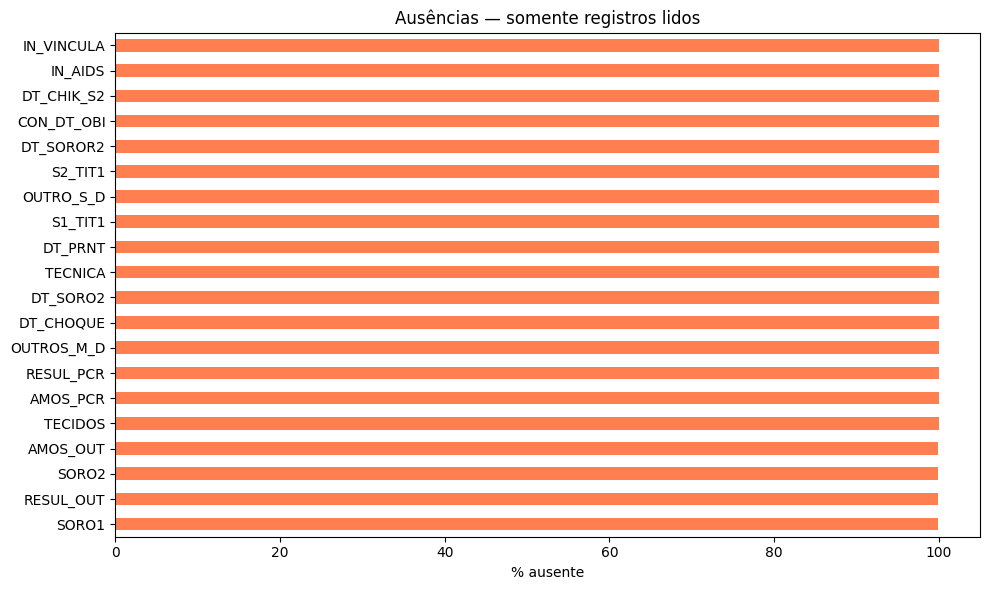

In [ ]:
# ================= CONFIGURAÇÃO DO PERCENTUAL =================
PERCENTUAL_BASE = 10  # 0.1 = 0,1%; 1 = 1%; 10 = 10%; 100 = tudo
TOTAL_REGISTROS_REFERENCIA = 32_512_002  # usado se não houver manifesto

# CÉLULA ÚNICA — LEITURA LIMITADA PELO PERCENTUAL ESCOLHIDO
from pathlib import Path
import time
import math
import json
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display

# ================= CONFIGURAÇÃO =================
if not math.isfinite(PERCENTUAL_BASE) or not 0 < PERCENTUAL_BASE <= 100:
    raise ValueError("PERCENTUAL_BASE deve ser maior que 0 e até 100.")

CSV = Path(globals().get(
    "CSV_FINAL",
    "/content/sinan-dengue/dados/dengue-completo.csv"
))

PASTA_ZIPS = Path("/content/sinan-dengue/dados/zips")

AUSENCIAS = [
    "", "nan", "NaN", "NAN", "null", "NULL",
    "None", "none", "NaT", "<NA>"
]

inicio = time.perf_counter()

opcoes = dict(
    dtype=str,
    keep_default_na=False,
    na_values=AUSENCIAS,
    encoding="utf-8-sig",
    sep=",",
)

# ============== LEITURA LIMITADA ==============
# Procura ZIPs locais sem ler seu conteúdo completo.
candidatos = list(PASTA_ZIPS.glob("*.zip"))
candidatos += list((CSV.parent / "zips").glob("*.zip"))

def ano_zip(caminho):
    nome = caminho.name
    match = re.search(r"DENGBR(\d{2})", nome, re.I)
    if match:
        return 2000 + int(match.group(1))
    match = re.search(r"\b(20\d{2}|19\d{2})\b", nome)
    return int(match.group(1)) if match else None

# Evita incluir duas cópias do mesmo arquivo anual.
arquivos_anuais = {}
for caminho in candidatos:
    ano = ano_zip(caminho)
    if ano is not None:
        arquivos_anuais.setdefault(ano, caminho)

# Apenas lê o manifesto pequeno, sem contar linhas do CSV gigante.
contagens = {}
manifesto_path = CSV.with_suffix(".manifest.json")
if manifesto_path.is_file():
    manifesto = json.loads(manifesto_path.read_text())
    contagens = {
        int(ano): int(quantidade)
        for ano, quantidade in manifesto.get("por_ano_arquivo", {}).items()
    }

TOTAL_BASE = sum(contagens.values()) if contagens else TOTAL_REGISTROS_REFERENCIA
LIMITE_PREVIA_CSV = math.ceil(TOTAL_BASE * PERCENTUAL_BASE / 100)
print(f"Percentual escolhido: {PERCENTUAL_BASE:g}%")
print(f"Quantidade-alvo da base completa: {LIMITE_PREVIA_CSV:,} registros")

partes = []

if arquivos_anuais:
    anos = sorted(arquivos_anuais)
    if all(ano in contagens for ano in anos):
        # Distribuição proporcional ao tamanho real de cada arquivo anual.
        # Arredondamento pelo maior resto mantém o orçamento total de linhas.
        fracoes = {ano: contagens[ano] * PERCENTUAL_BASE / 100 for ano in anos}
        limites = {ano: math.floor(fracoes[ano]) for ano in anos}
        alvo_disponivel = math.ceil(sum(contagens[ano] for ano in anos) * PERCENTUAL_BASE / 100)
        sobra = alvo_disponivel - sum(limites.values())
        ordem = sorted(anos, key=lambda ano: (-(fracoes[ano] - limites[ano]), ano))
        for ano in ordem[:sobra]:
            limites[ano] += 1
        print("Distribuição proporcional por ano, usando o manifesto.")
        if set(contagens) - set(anos):
            print("ATENÇÃO: faltam ZIPs de alguns anos; a leitura cobre apenas os disponíveis.")
    else:
        # Sem contagens, orçamento total dividido igualmente entre os anos.
        quota, sobra = divmod(LIMITE_PREVIA_CSV, len(anos))
        limites = {ano: quota + int(i < sobra) for i, ano in enumerate(anos)}
        print("Sem contagens por ano: orçamento dividido igualmente entre os ZIPs.")
        print("Arquivos pequenos podem fazer o total lido ficar abaixo da meta.")

    print("Lendo somente o início de cada ZIP anual...", flush=True)

    for ano, caminho in sorted(arquivos_anuais.items()):
        restantes = limites[ano]
        if restantes == 0:
            continue

        with zipfile.ZipFile(caminho) as z:
            membros = sorted(
                nome for nome in z.namelist()
                if nome.lower().endswith(".csv")
                and not nome.endswith("/")
            )

            for membro in membros:
                if restantes <= 0:
                    break

                with z.open(membro) as origem:
                    parte = pd.read_csv(
                        origem, nrows=restantes, **opcoes
                    )

                parte.columns = parte.columns.str.strip().str.upper()
                parte["ANO_ARQUIVO"] = str(ano)
                partes.append(parte)
                restantes -= len(parte)

    if not partes:
        raise ValueError("Os ZIPs encontrados não contêm CSVs utilizáveis.")

    dados = pd.concat(partes, ignore_index=True, sort=False)
    origem_analise = "Prévia do início de cada arquivo anual"

else:
    if not CSV.is_file():
        from google.colab import drive
        drive.mount("/content/drive")
        CSV = Path(
            "/content/drive/MyDrive/Denguinhos/"
            "datasets/dengue-completo.csv"
        )

    print(
        "ZIPs anuais não encontrados. "
        "Lendo somente o início do CSV gigante...",
        flush=True,
    )

    dados = pd.read_csv(
        CSV, nrows=LIMITE_PREVIA_CSV, **opcoes
    )
    dados.columns = dados.columns.str.strip().str.upper()
    origem_analise = "Prévia inicial do CSV — pode conter apenas os primeiros anos"

print(f"\n{origem_analise}")
print(f"Linhas lidas: {len(dados):,}")
print(f"Percentual efetivamente lido sobre a base de referência: {len(dados) / TOTAL_BASE * 100:.4f}%")
print("Leitura do início dos arquivos; não é uma amostra aleatória.")
print(f"Colunas: {len(dados.columns)}")
print(f"Leitura concluída em {time.perf_counter() - inicio:.1f}s")
print("ATENÇÃO: resultados abaixo se referem somente à prévia.\n")

if dados.empty:
    raise ValueError("Nenhum registro disponível para análise.")

# ================= AUSÊNCIAS =================
perfil = pd.DataFrame({
    "ausentes": dados.isna().sum(),
    "percentual_ausente": dados.isna().mean().mul(100),
    "valores_distintos": dados.nunique(dropna=True),
}).sort_values("percentual_ausente", ascending=False)

print("ATRIBUTOS — PRÉVIA")
display(perfil.head(30).round(2))

perfil.head(20)["percentual_ausente"].sort_values().plot.barh(
    figsize=(10, 6),
    color="coral",
    title="Ausências — somente registros lidos",
)
plt.xlabel("% ausente")
plt.tight_layout()
plt.show()

# ================= DUPLICATAS =================
originais = [c for c in dados.columns if c != "ANO_ARQUIVO"]

duplicados = dados.duplicated(
    subset=originais, keep=False
)

print("\nDUPLICATAS — SOMENTE REGISTROS LIDOS")
print("Linhas envolvidas:", int(duplicados.sum()))
print(
    "Cópias excedentes:",
    int(dados.duplicated(subset=originais).sum()),
)

if duplicados.any():
    display(dados.loc[duplicados].head(10))

# ================= ANOS COBERTOS =================
if "ANO_ARQUIVO" in dados.columns:
    print("\nCOBERTURA DA PRÉVIA — NÃO É O VOLUME REAL POR ANO")
    display(
        dados["ANO_ARQUIVO"]
        .value_counts()
        .sort_index()
        .rename("linhas_lidas")
        .to_frame()
    )

# ================= FREQUÊNCIAS =================
for campo in ["CS_SEXO", "CLASSI_FIN", "EVOLUCAO"]:
    if campo in dados.columns:
        print(f"\n{campo} — PRÉVIA")
        display(
            dados[campo]
            .fillna("AUSENTE")
            .value_counts()
            .head(15)
            .to_frame("quantidade")
        )

# ================= CORRELAÇÕES =================
# Aplicável aos campos cujo dicionário confirma:
# 1 = sim, 2 = não. Outros códigos ficam ausentes.
campos = [
    "FEBRE", "MIALGIA", "CEFALEIA", "EXANTEMA",
    "VOMITO", "NAUSEA", "DOR_COSTAS", "ARTRITE",
    "ARTRALGIA", "LEUCOPENIA", "DOR_RETRO",
    "DIABETES", "HEMATOLOG", "HEPATOPAT",
    "RENAL", "HIPERTENSA", "AUTO_IMUNE",
]

binarios = pd.DataFrame({
    campo: pd.to_numeric(dados[campo], errors="coerce")
             .map({1: 1.0, 2: 0.0})
    for campo in campos if campo in dados.columns
})

if len(binarios.columns) >= 2:
    correlacoes = binarios.corr(min_periods=500)
    utilizaveis = correlacoes.notna().any()
    correlacoes = correlacoes.loc[utilizaveis, utilizaveis]

    if not correlacoes.empty:
        plt.figure(figsize=(11, 8))
        sns.heatmap(
            correlacoes,
            cmap="coolwarm",
            center=0,
            vmin=-1,
            vmax=1,
        )
        plt.title("Coeficiente phi — somente a prévia")
        plt.tight_layout()
        plt.show()
    else:
        print("\nDados válidos insuficientes para correlações.")

# ================= DATAS =================
datas = {}

for campo in ["DT_NOTIFIC", "DT_SIN_PRI"]:
    if campo in dados.columns:
        datas[campo] = pd.to_datetime(
            dados[campo],
            format="%Y-%m-%d",
            errors="coerce",
        )

        invalidas = dados[campo].notna() & datas[campo].isna()

        print(
            f"\n{campo}: "
            f"{invalidas.sum():,} valores não interpretados; "
            f"intervalo observado: {datas[campo].min()} "
            f"até {datas[campo].max()}"
        )

if {"DT_NOTIFIC", "DT_SIN_PRI"}.issubset(datas):
    negativas = (
        datas["DT_NOTIFIC"] - datas["DT_SIN_PRI"]
    ).dt.days < 0

    print(
        "Notificações anteriores aos sintomas:",
        int(negativas.sum()),
    )

    if negativas.any():
        display(
            dados.loc[
                negativas, ["DT_SIN_PRI", "DT_NOTIFIC"]
            ].head(10)
        )

# ================= ASSOCIAÇÃO CATEGÓRICA =================
if {"CS_SEXO", "CLASSI_FIN"}.issubset(dados.columns):
    pares = dados[["CS_SEXO", "CLASSI_FIN"]].dropna()
    pares = pares.loc[pares["CS_SEXO"].isin(["M", "F"])]

    tabela = pd.crosstab(
        pares["CS_SEXO"], pares["CLASSI_FIN"]
    )

    if min(tabela.shape) >= 2:
        chi2, p, _, esperadas = chi2_contingency(
            tabela, correction=False
        )

        n = tabela.to_numpy().sum()
        v = np.sqrt(
            chi2 / (n * (min(tabela.shape) - 1))
        )

        print("\nSexo × classificação — PRÉVIA")
        print(f"p-valor: {p:.3g}")
        print(f"V de Cramér: {v:.3f}")
        print(
            "Células com frequência esperada < 5:",
            f"{(esperadas < 5).mean():.1%}",
        )
        display(tabela)

print(f"\nTempo total: {time.perf_counter() - inicio:.1f}s")
print(
    "Os dados analisados permanecem na variável 'dados'. "
    "Nenhuma contagem global foi executada. Percentuais altos aumentam tempo e RAM."
)


In [4]:
# ================= CONFIGURAÇÃO =================
# Usando DuckDB para ler diretamente do arquivo CSV físico sem estourar a RAM
import duckdb
from pathlib import Path
from IPython.display import display

CAMINHO_CSV = globals().get("CSV_FINAL", Path("/content/sinan-dengue/dados/dengue-completo.csv"))
CODIGO_MUNICIPIO = "2611606"  # Exemplo: Recife
CAMPO_MUNICIPIO = "ID_MN_RESI"  # Município de residência

if not CAMINHO_CSV.is_file():
    raise FileNotFoundError(f"Arquivo CSV não encontrado em {CAMINHO_CSV}. Execute as etapas anteriores primeiro.")

codigo = str(CODIGO_MUNICIPIO).strip()[:6]
if not codigo.isdigit() or len(codigo) < 6:
    raise ValueError("Informe um código municipal de pelo menos 6 dígitos.")

print(f"Analisando arquivo completo de forma otimizada e tolerante a falhas: {CAMINHO_CSV}")
print(f"Filtrando por {CAMPO_MUNICIPIO} iniciando com: {codigo}")

# Conexão temporária do DuckDB
con = duckdb.connect()
try:
    # Otimizações de execução para leitura ultra rápida do CSV
    con.execute("SET memory_limit = '4GB'")
    con.execute("SET preserve_insertion_order = false")

    # Criamos uma view temporária para ler os dados ignorando registros com defeito de formatação estrutural (ex: vírgulas soltas adicionais)
    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW base_csv AS
        SELECT ANO_ARQUIVO, \"{CAMPO_MUNICIPIO}\" AS cod_mun
        FROM read_csv('{str(CAMINHO_CSV)}', header=true, delim=',', all_varchar=true, parallel=true, ignore_errors=true)
    """)

    # Buscamos a contagem por ano em uma única varredura ultra rápida.
    query_anos = f"""
        SELECT
            ANO_ARQUIVO as ano,
            COUNT(*) as notificacoes
        FROM base_csv
        WHERE cod_mun LIKE '{codigo}%'
           OR cod_mun LIKE '{codigo}.0%'
        GROUP BY ANO_ARQUIVO
        ORDER BY ANO_ARQUIVO
    """
    df_anos = con.execute(query_anos).df()

    if not df_anos.empty:
        total_notificacoes = df_anos['notificacoes'].sum()
        print(f"\nTotal de notificações: {total_notificacoes:,}")
        df_anos = df_anos.set_index('ano')
        display(df_anos)
    else:
        print("\nTotal de notificações: 0")
        print("Nenhum registro encontrado para este município.")

finally:
    con.close()

Analisando arquivo completo de forma otimizada e tolerante a falhas: /content/sinan-dengue/dados/dengue-completo.csv
Filtrando por ID_MN_RESI iniciando com: 261160


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Total de notificações: 199,080


,notificacoes
ano,
2000,2654
2001,3407
2002,39705
2003,1215
2004,866
2005,1809
2006,3233
2007,4054
2008,8712


Analisando arquivo completo com DuckDB: /content/sinan-dengue/dados/dengue-completo.csv
Agregando dados geograficamente... (isso pode levar de 30 a 60 segundos)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,notificacoes,percentual_do_total
regiao,,
Norte,1654781,5.09
Nordeste,5598858,17.22
Sudeste,17297868,53.20
Sul,3501255,10.77
Centro-Oeste,4454569,13.70
Não identificada,4670,0.01


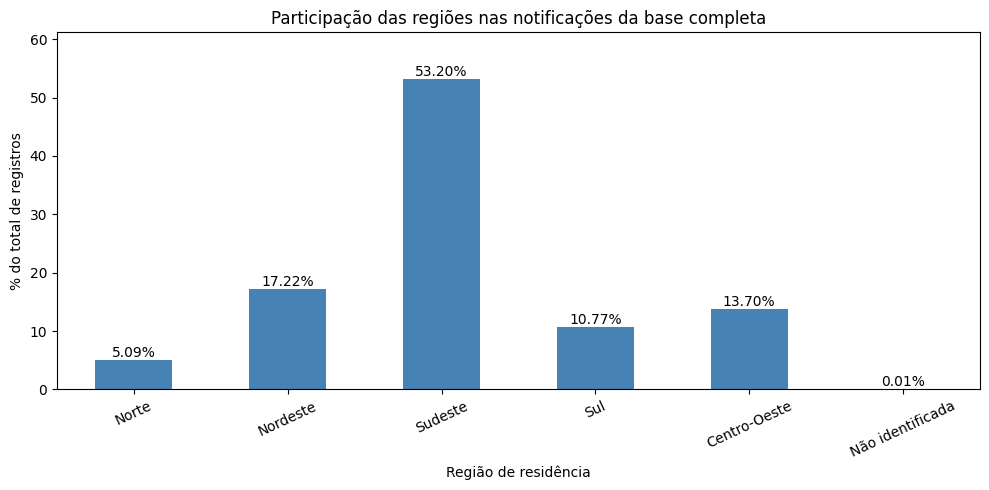

Total analisado: 32,512,001
Localização não identificada: 4,670
Tempo: 157.7s


In [6]:
# ================= CONFIGURAÇÃO =================
import duckdb
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CAMINHO_CSV = globals().get("CSV_FINAL", Path("/content/sinan-dengue/dados/dengue-completo.csv"))
TOTAL_ESPERADO = 32_512_002

if not CAMINHO_CSV.is_file():
    raise FileNotFoundError(f"Arquivo CSV não encontrado em {CAMINHO_CSV}. Execute as etapas anteriores primeiro.")

inicio = time.perf_counter()
print(f"Analisando arquivo completo com DuckDB: {CAMINHO_CSV}")

# Grupos regionais para mapeamento
grupos = {
    "Norte": ["RO", "11", "AC", "12", "AM", "13", "RR", "14", "PA", "15", "AP", "16", "TO", "17"],
    "Nordeste": ["MA", "21", "PI", "22", "CE", "23", "RN", "24", "PB", "25", "PE", "26", "AL", "27", "SE", "28", "BA", "29"],
    "Sudeste": ["MG", "31", "ES", "32", "RJ", "33", "SP", "35"],
    "Sul": ["PR", "41", "SC", "42", "RS", "43"],
    "Centro-Oeste": ["MS", "50", "MT", "51", "GO", "52", "DF", "53"]
}

# Conectar ao DuckDB
con = duckdb.connect()
try:
    # Otimizações para economizar RAM do Colab
    con.execute("SET memory_limit = '4GB'")
    con.execute("SET preserve_insertion_order = false")

    # Registra a base do CSV de forma otimizada (apenas as colunas necessárias para o agrupamento regional)
    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW base_csv AS
        SELECT
            TRY_CAST(REGEXP_REPLACE(TRIM(\"SG_UF\"), '\\.0+$', '') AS VARCHAR) as sg_uf,
            TRY_CAST(REGEXP_REPLACE(TRIM(\"ID_MN_RESI\"), '\\.0+$', '') AS VARCHAR) as id_mn_resi
        FROM read_csv('{str(CAMINHO_CSV)}', header=true, delim=',', all_varchar=true, parallel=true, ignore_errors=true)
    """)

    # Obtemos a frequência combinada para fazer a classificação de forma instantânea na memória
    print("Agregando dados geograficamente... (isso pode levar de 30 a 60 segundos)")
    df_agrupado = con.execute("""
        SELECT sg_uf, id_mn_resi, COUNT(*) as qtd
        FROM base_csv
        GROUP BY sg_uf, id_mn_resi
    """).df()

finally:
    con.close()

# Processamento pós-agregação das regiões via Python (extremamente rápido e leve)
mapa = {item: reg for reg, itens in grupos.items() for item in itens}
contagem = {regiao: 0 for regiao in grupos}
sem_regiao = 0
total_calculado = 0

for idx, row in df_agrupado.iterrows():
    uf = str(row['sg_uf']).strip().upper() if pd.notna(row['sg_uf']) else ""
    mun = str(row['id_mn_resi']).strip() if pd.notna(row['id_mn_resi']) else ""
    qtd = int(row['qtd'])
    total_calculado += qtd

    regiao = mapa.get(uf)
    if regiao is not None:
        contagem[regiao] += qtd
    else:
        # Tenta inferir pela UF do município de residência (dois primeiros dígitos)
        reg_mun = mapa.get(mun[:2]) if len(mun) >= 2 and mun[:2].isdigit() else None
        if reg_mun is not None:
            contagem[reg_mun] += qtd
        else:
            sem_regiao += qtd

contagem["Não identificada"] = sem_regiao

# ================= RESULTADO =================
resultado_regioes = (
    pd.Series(contagem, name="notificacoes")
    .rename_axis("regiao")
    .to_frame()
)

resultado_regioes["percentual_do_total"] = (
    resultado_regioes["notificacoes"] / total_calculado * 100
)

assert resultado_regioes["notificacoes"].sum() == total_calculado

display(resultado_regioes.round(2))

# Plotagem dos resultados
ax = resultado_regioes["percentual_do_total"].plot.bar(
    figsize=(10, 5),
    color="steelblue",
    title="Participação das regiões nas notificações da base completa",
)

for barra in ax.patches:
    ax.annotate(
        f"{barra.get_height():.2f}%",
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
    )

plt.ylabel("% do total de registros")
plt.xlabel("Região de residência")
plt.xticks(rotation=25)
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

print(f"Total analisado: {total_calculado:,}")
print(f"Localização não identificada: {sem_regiao:,}")
print(f"Tempo: {time.perf_counter() - inicio:.1f}s")